In [18]:
import sys
print(sys.executable)

C:\Users\Bima Sena\uts-graf\myvenv\Scripts\python.exe


In [19]:
import pandas as pd

df = pd.read_csv("data/events.csv")
df["waktu"] = pd.to_datetime(df["timestamp"], unit="ms")

print(df["waktu"].min())
print(df["waktu"].max())
print(df["waktu"].dt.to_period("M").value_counts().sort_index())

2015-05-03 03:00:04.384000
2015-09-18 02:59:47.788000
waktu
2015-05    590652
2015-06    610393
2015-07    697984
2015-08    553362
2015-09    303710
Freq: M, Name: count, dtype: int64


## 2.1 Wrangling dan EDA

### Nomor 1 dan 2: Periode waktu dan filter data


**Jawaban nomor 1.** Saya memilih P1 pada 9 Mei sampai 26 Juni 2015 (49 hari) sebagai data training, dan P2 pada 27 Juni sampai 5 Agustus 2015 (40 hari) sebagai data testing. P2 dimulai tepat sehari setelah P1 berakhir, jadi kedua periode tidak tumpang tindih dan data testing tidak ikut masuk ke data training. P1 sengaja dibuat lebih panjang supaya graf yang terbentuk cukup padat. Kombinasi tanggal ini sudah saya bandingkan dengan periode milik beberapa teman satu kelas dan tidak ada yang sama.

**Jawaban nomor 2.** Cell melakukan filter pada kolom `timestamp`. Karena nilainya dalam milidetik, tanggal batas diubah dulu ke milidetik lewat fungsi `ke_ms`. Pada batas akhir saya tambahkan satu hari lalu dikurangi satu milidetik, supaya seluruh hari terakhir (26 Juni dan 5 Agustus) ikut terhitung. Hasil filter disimpan ke `data_p1/events.csv` dan `data_p2/events.csv`.

In [20]:
import os

p1_mulai = "2015-05-09"
p1_selesai = "2015-06-26"
p2_mulai = "2015-06-27"
p2_selesai = "2015-08-05"

def ke_ms(tanggal, akhir_hari=False):
    waktu = pd.Timestamp(tanggal)
    if akhir_hari:
        waktu = waktu + pd.Timedelta(days=1) - pd.Timedelta(milliseconds=1)
    return int(waktu.value // 10**6)

p1 = df[(df["timestamp"] >= ke_ms(p1_mulai)) & (df["timestamp"] <= ke_ms(p1_selesai, True))]
p2 = df[(df["timestamp"] >= ke_ms(p2_mulai)) & (df["timestamp"] <= ke_ms(p2_selesai, True))]

p1 = p1.drop(columns=["waktu"])
p2 = p2.drop(columns=["waktu"])

os.makedirs("data_p1", exist_ok=True)
os.makedirs("data_p2", exist_ok=True)

p1.to_csv("data_p1/events.csv", index=False)
p2.to_csv("data_p2/events.csv", index=False)

print("P1:", p1.shape)
print("P2:", p2.shape)
print(p1["event"].value_counts())
print(p2["event"].value_counts())

P1: (1001321, 5)
P2: (868676, 5)
event
view           968775
addtocart       24500
transaction      8046
Name: count, dtype: int64
event
view           839843
addtocart       21658
transaction      7175
Name: count, dtype: int64


Hasilnya, P1 berisi 1.001.321 baris (view 968.775, addtocart 24.500, transaction 8.046) dan P2 berisi 868.676 baris (view 839.843, addtocart 21.658, transaction 7.175). Kolom bantu `waktu` dibuang sebelum disimpan, jadi kedua file CSV memiliki kolom yang sama dengan data asli.

In [21]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\Bima Sena\uts-graf
['.ipynb_checkpoints', 'data', 'data_p1', 'data_p2', 'ecommerce-dataset.zip', 'import_data.py', 'myvenv', 'requirements.txt', 'sebelum.png', 'sesudah.png', 'tutorial_neo4j.py', 'uts_GrafSD.ipynb', 'UTS_GSD.ipynb']


In [22]:
import pandas as pd

df = pd.read_csv("data/events.csv")

p1_mulai = "2015-05-09"
p1_selesai = "2015-06-26"
p2_mulai = "2015-06-27"
p2_selesai = "2015-08-05"

def ke_ms(tanggal, akhir_hari=False):
    waktu = pd.Timestamp(tanggal)
    if akhir_hari:
        waktu = waktu + pd.Timedelta(days=1) - pd.Timedelta(milliseconds=1)
    return int(waktu.value // 10**6)

p1 = df[(df["timestamp"] >= ke_ms(p1_mulai)) & (df["timestamp"] <= ke_ms(p1_selesai, True))]
p2 = df[(df["timestamp"] >= ke_ms(p2_mulai)) & (df["timestamp"] <= ke_ms(p2_selesai, True))]

os.makedirs("data_p1", exist_ok=True)
os.makedirs("data_p2", exist_ok=True)

p1.to_csv("data_p1/events.csv", index=False)
p2.to_csv("data_p2/events.csv", index=False)

print("P1:", p1.shape)
print("P2:", p2.shape)

P1: (1001321, 5)
P2: (868676, 5)


In [23]:
isi = open("import_data.py").read()
isi = isi.replace("total_rows = 2756101", "total_rows = 1001321")
open("import_data.py", "w").write(isi)

3165

In [10]:
import getpass
password = getpass.getpass("Password Neo4j: ")


Password Neo4j:  ········


membuat koneksi ke Neo4j lalu menghitung jumlah simpul untuk memastikan database sudah kosong. Hasilnya 0, jadi database siap diisi.

In [24]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver("neo4j://127.0.0.1:7687", auth=("neo4j", password))

with driver.session() as session:
    hasil = session.run("MATCH (n) RETURN count(n) AS jumlah")
    print(hasil.single()["jumlah"])

driver.close()

659541


Impor dijalankan dengan `%run import_data.py` memakai folder `data_p1` sebagai sumber. Data dibaca per 10.000 baris (101 batch) dan tiap batch dikirim ke Neo4j dengan `execute_write`. Di dalam query CYPHER, `MERGE` dipakai untuk membuat simpul `Visitor` dan `Item` tanpa duplikat, lalu relasi dibuat sesuai jenis event: `view` menjadi `VIEWED`, `addtocart` menjadi `ADDED_TO_CART`, dan `transaction` menjadi `BOUGHT`. Peringatan *deprecated* pada output berasal dari sintaks `CALL` di kode soal dan tidak memengaruhi hasil impor.

In [25]:
%run import_data.py -u neo4j -p $password -s data_p1

Membaca file data dari: data_p1\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 101/101 [02:22<00:00,  1.41s/it]

Proses impor berhasil.


memeriksa hasil impor dengan menghitung simpul dan relasi di database.

In [26]:
driver = GraphDatabase.driver("neo4j://127.0.0.1:7687", auth=("neo4j", password))

with driver.session() as session:
    for baris in session.run("MATCH (n) RETURN labels(n) AS jenis, count(*) AS jumlah"):
        print(baris["jenis"], baris["jumlah"])
    for baris in session.run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah"):
        print(baris["relasi"], baris["jumlah"])

driver.close()

['Visitor'] 509883
['Item'] 149658
VIEWED 2906325
ADDED_TO_CART 73500
BOUGHT 24138
SIMILAR_TO 5


Terdapat 509.883 simpul `Visitor` dan 149.658 simpul `Item`. Jumlah relasinya sama dengan jumlah event pada P1 (968.775 `VIEWED`, 24.500 `ADDED_TO_CART`, dan 8.046 `BOUGHT`), jadi semua data berhasil masuk tanpa ada yang hilang atau terhitung dua kali.

### Nomor 3: Komposisi subgraph

In [27]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver("neo4j://127.0.0.1:7687", auth=("neo4j", password))

menghitung jumlah simpul untuk setiap label (jenis simpul).

In [28]:
query_simpul = """
MATCH (n)
UNWIND labels(n) AS jenis
RETURN jenis, count(*) AS jumlah
ORDER BY jumlah DESC
"""

with driver.session() as session:
    hasil = session.run(query_simpul)
    data_simpul = [(baris["jenis"], baris["jumlah"]) for baris in hasil]

tabel_simpul = pd.DataFrame(data_simpul, columns=["jenis_simpul", "jumlah"])
print(tabel_simpul)
print("Total simpul:", tabel_simpul["jumlah"].sum())

  jenis_simpul  jumlah
0      Visitor  509883
1         Item  149658
Total simpul: 659541


menghitung jumlah relasi untuk setiap kombinasi simpul asal, jenis relasi, dan simpul tujuan, sebagai pelengkap komposisi subgraph.

In [29]:
query_relasi = """
MATCH (a)-[r]->(b)
RETURN labels(a)[0] AS dari, type(r) AS relasi, labels(b)[0] AS ke, count(*) AS jumlah
ORDER BY jumlah DESC
"""

with driver.session() as session:
    hasil = session.run(query_relasi)
    data_relasi = [(b["dari"], b["relasi"], b["ke"], b["jumlah"]) for b in hasil]

tabel_relasi = pd.DataFrame(data_relasi, columns=["dari", "relasi", "ke", "jumlah"])
print(tabel_relasi)
print("Total relasi:", tabel_relasi["jumlah"].sum())

      dari         relasi       ke   jumlah
0  Visitor         VIEWED     Item  2906325
1  Visitor  ADDED_TO_CART     Item    73500
2  Visitor         BOUGHT     Item    24138
3  Visitor     SIMILAR_TO  Visitor        5
Total relasi: 3003968


#### Jawaban nomor 3

Subgraph dari data P1 terdiri atas dua jenis simpul, yaitu `Visitor` sebanyak 509.883 dan `Item` sebanyak 149.658, sehingga totalnya 659.541 simpul. Relasinya ada tiga jenis dan semuanya berarah dari `Visitor` ke `Item`: `VIEWED` 968.775, `ADDED_TO_CART` 24.500, dan `BOUGHT` 8.046, dengan total 1.001.321 relasi. Sekitar 97 persen relasi adalah `VIEWED`.

Query untuk menghitung jumlah simpul:

```cypher
MATCH (n)
UNWIND labels(n) AS jenis
RETURN jenis, count(*) AS jumlah
ORDER BY jumlah DESC
```

`MATCH (n)` mengambil semua simpul di graf, dengan `n` sebagai variabelnya. Fungsi `labels(n)` mengembalikan daftar label dari sebuah simpul, sehingga saya memakai `UNWIND` untuk memecah daftar itu menjadi satu baris per label. Setelah itu `count(*)` menghitung banyaknya baris untuk tiap label. Di CYPHER tidak ada `GROUP BY` seperti di SQL, karena pengelompokan otomatis dilakukan berdasarkan kolom yang bukan fungsi agregat, yaitu `jenis`. Terakhir, `ORDER BY jumlah DESC` mengurutkan hasil dari jumlah terbesar.

Query untuk menghitung relasi:

```cypher
MATCH (a)-[r]->(b)
RETURN labels(a)[0] AS dari, type(r) AS relasi, labels(b)[0] AS ke, count(*) AS jumlah
ORDER BY jumlah DESC
```

Pola `(a)-[r]->(b)` mencocokkan setiap relasi berarah dari simpul `a` ke simpul `b`. `type(r)` mengambil nama jenis relasinya, sedangkan `labels(a)[0]` dan `labels(b)[0]` mengambil label simpul di kedua ujungnya. Hasilnya dihitung untuk setiap kombinasi asal, relasi, dan tujuan.

Dari sisi Python, query dikirim dengan `session.run()`. Setiap baris hasil dibaca menggunakan nama kolom, misalnya `baris["jumlah"]`, lalu dimasukkan ke DataFrame pandas supaya tampil rapi.

### Nomor 4: VSM untuk simpul User



In [30]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
query_matriks = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitor, i.itemId AS item, count(r) AS bobot
"""

with driver.session() as session:
    hasil = session.run(query_matriks)
    data_matriks = [(b["visitor"], b["item"], b["bobot"]) for b in hasil]

tabel_vsm = pd.DataFrame(data_matriks, columns=["visitor", "item", "bobot"])
print(tabel_vsm.shape)
print(tabel_vsm.head())

(773006, 3)
   visitor    item  bobot
0   257597  355908      3
1   979686  355908      3
2   627902  355908      3
3   561023  355908      3
4   981382  355908      3


matriks dibentuk dalam format CSR. `pd.factorize` mengubah ID visitor dan ID item menjadi nomor baris dan kolom yang berurutan. Setelah itu saya menghitung shape, jumlah elemen tidak nol, density, sparsity, dan statistik jumlah item per user.

In [32]:
from scipy.sparse import csr_matrix
import numpy as np

baris, daftar_visitor = pd.factorize(tabel_vsm["visitor"])
kolom, daftar_item = pd.factorize(tabel_vsm["item"])

matriks_user = csr_matrix(
    (tabel_vsm["bobot"], (baris, kolom)),
    shape=(len(daftar_visitor), len(daftar_item))
)

print("Shape:", matriks_user.shape)
print("Dimensi vektor (jumlah item):", matriks_user.shape[1])
print("Jumlah elemen tidak nol:", matriks_user.nnz)

kepadatan = matriks_user.nnz / (matriks_user.shape[0] * matriks_user.shape[1])
print("Density:", kepadatan)
print("Sparsity:", 1 - kepadatan)

item_per_user = np.diff(matriks_user.indptr)
print(pd.Series(item_per_user).describe())
print("User yang hanya berinteraksi dengan 1 item:", (item_per_user == 1).sum())

Shape: (509883, 149658)
Dimensi vektor (jumlah item): 149658
Jumlah elemen tidak nol: 773006
Density: 1.0130068809998458e-05
Sparsity: 0.99998986993119
count    509883.000000
mean          1.516046
std           5.378825
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max        1230.000000
dtype: float64
User yang hanya berinteraksi dengan 1 item: 407118


saya memplot contoh kecil berupa 10 user acak (`random.seed(42)`) yang punya minimal 3 item. Simpul biru adalah user dan simpul oranye adalah item.

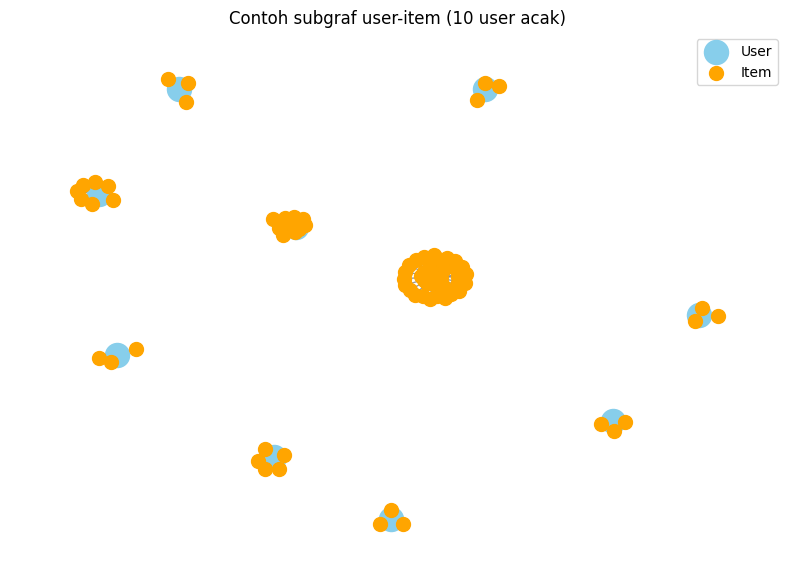

Simpul di plot: 84
Relasi di plot: 74


In [33]:
import networkx as nx
import matplotlib.pyplot as plt
import random

random.seed(42)
calon_user = [u for u in range(matriks_user.shape[0]) if item_per_user[u] >= 3]
contoh_user = random.sample(calon_user, 10)

graf_contoh = nx.Graph()
simpul_user = []

for u in contoh_user:
    nama_user = "U" + str(daftar_visitor[u])
    simpul_user.append(nama_user)
    mulai = matriks_user.indptr[u]
    akhir = matriks_user.indptr[u + 1]
    for k, w in zip(matriks_user.indices[mulai:akhir], matriks_user.data[mulai:akhir]):
        graf_contoh.add_edge(nama_user, "I" + str(daftar_item[k]), weight=w)

simpul_item = [n for n in graf_contoh.nodes if n not in simpul_user]
posisi = nx.spring_layout(graf_contoh, seed=42)

plt.figure(figsize=(10, 7))
nx.draw_networkx_nodes(graf_contoh, posisi, nodelist=simpul_user, node_color="skyblue", node_size=300, label="User")
nx.draw_networkx_nodes(graf_contoh, posisi, nodelist=simpul_item, node_color="orange", node_size=100, label="Item")
nx.draw_networkx_edges(graf_contoh, posisi, alpha=0.4)
plt.title("Contoh subgraf user-item (10 user acak)")
plt.legend()
plt.axis("off")
plt.show()

print("Simpul di plot:", graf_contoh.number_of_nodes())
print("Relasi di plot:", graf_contoh.number_of_edges())

#### Karakteristik VSM user

Matriks user x item berukuran 509.883 x 149.658, jadi setiap user direpresentasikan sebagai vektor berdimensi 149.658. Dari sekitar 76 miliar sel pada matriks itu, hanya 773.006 yang tidak nol, yaitu pasangan user-item yang unik. Total interaksinya 1.001.321, sehingga ada sekitar 228 ribu interaksi berulang pada pasangan yang sama. Density-nya sekitar 1,01 × 10⁻⁵ atau sparsity 99,999 persen, jadi matriks ini harus disimpan dalam format sparse. Kalau disimpan penuh, memorinya tidak akan cukup.

Sebaran jumlah item per user sangat timpang. Rata-rata satu user hanya berinteraksi dengan 1,52 item, nilai tengahnya 1, dan kuartil ketiganya pun masih 1. Sebanyak 407.118 user (79,85 persen) hanya berinteraksi dengan satu item, sedangkan user paling aktif menyentuh 1.230 item. Pola seperti ini disebut long tail.

Pada plot networkx, 10 user contoh membentuk 84 simpul dan 74 relasi. Setiap item hanya terhubung ke satu user, sehingga graf terpecah menjadi 10 kelompok yang tidak saling terhubung. Artinya, di antara user contoh tidak ada item yang dipakai bersama. Perlu diingat bahwa user pada plot dipilih yang punya minimal 3 item, jadi kondisi sebenarnya lebih jarang daripada yang tampak di gambar.

### Nomor 5: VSM untuk simpul Item


In [34]:
matriks_item = matriks_user.T.tocsr()

print("Shape:", matriks_item.shape)
print("Dimensi vektor (jumlah user):", matriks_item.shape[1])
print("Jumlah elemen tidak nol:", matriks_item.nnz)

kepadatan_item = matriks_item.nnz / (matriks_item.shape[0] * matriks_item.shape[1])
print("Density:", kepadatan_item)
print("Sparsity:", 1 - kepadatan_item)

user_per_item = np.diff(matriks_item.indptr)
print(pd.Series(user_per_item).describe())
print("Item yang hanya disentuh 1 user:", (user_per_item == 1).sum())

Shape: (149658, 509883)
Dimensi vektor (jumlah user): 509883
Jumlah elemen tidak nol: 773006
Density: 1.0130068809998458e-05
Sparsity: 0.99998986993119
count    149658.000000
mean          5.165150
std          13.146888
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max        1077.000000
dtype: float64
Item yang hanya disentuh 1 user: 65900


Plot contoh untuk item menggunakan 10 item acak (`random.seed(42)`) yang punya 3 sampai 30 user. Batas atas 30 saya pasang supaya gambarnya tidak terlalu padat.

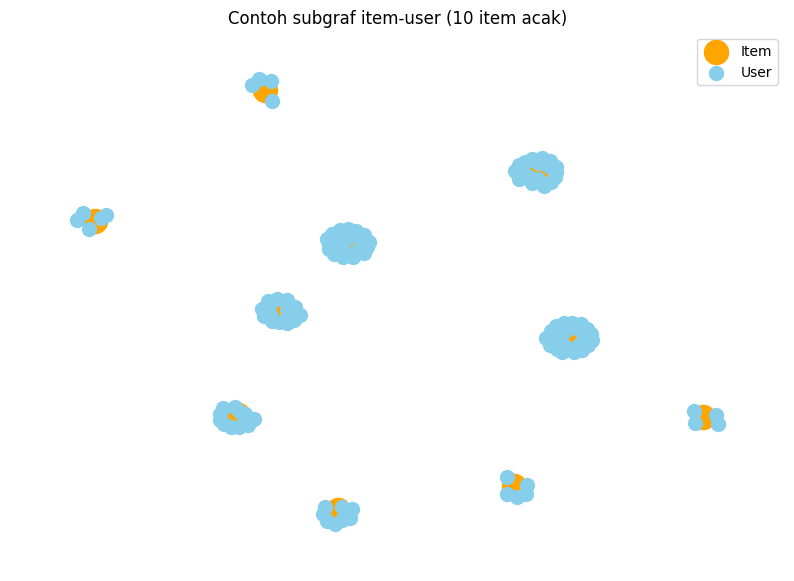

Simpul di plot: 120
Relasi di plot: 110


In [35]:
random.seed(42)
calon_item = [k for k in range(matriks_item.shape[0]) if 3 <= user_per_item[k] <= 30]
contoh_item = random.sample(calon_item, 10)

graf_item = nx.Graph()
simpul_item_contoh = []

for k in contoh_item:
    nama_item = "I" + str(daftar_item[k])
    simpul_item_contoh.append(nama_item)
    mulai = matriks_item.indptr[k]
    akhir = matriks_item.indptr[k + 1]
    for u, w in zip(matriks_item.indices[mulai:akhir], matriks_item.data[mulai:akhir]):
        graf_item.add_edge(nama_item, "U" + str(daftar_visitor[u]), weight=w)

simpul_user_contoh = [n for n in graf_item.nodes if n not in simpul_item_contoh]
posisi_item = nx.spring_layout(graf_item, seed=42)

plt.figure(figsize=(10, 7))
nx.draw_networkx_nodes(graf_item, posisi_item, nodelist=simpul_item_contoh, node_color="orange", node_size=300, label="Item")
nx.draw_networkx_nodes(graf_item, posisi_item, nodelist=simpul_user_contoh, node_color="skyblue", node_size=100, label="User")
nx.draw_networkx_edges(graf_item, posisi_item, alpha=0.4)
plt.title("Contoh subgraf item-user (10 item acak)")
plt.legend()
plt.axis("off")
plt.show()

print("Simpul di plot:", graf_item.number_of_nodes())
print("Relasi di plot:", graf_item.number_of_edges())

#### Karakteristik VSM item

Matriks item x user berukuran 149.658 x 509.883, sehingga tiap item adalah vektor berdimensi 509.883. Jumlah elemen tidak nol (773.006), density, dan sparsity sama persis dengan matriks user karena matriksnya memang sama dan hanya diputar. Perbedaannya ada pada sebaran: rata-rata satu item disentuh 5,17 user, nilai tengahnya 2, dan item paling populer disentuh 1.077 user. Item yang hanya disentuh satu user ada 65.900 (44,03 persen), jauh lebih sedikit dibanding proporsi user yang hanya menyentuh satu item (79,85 persen). Sebarannya tetap miring ke kanan, tetapi tidak sepincang pada sisi user.

Plot networkx memperlihatkan 10 item dengan 110 user di sekelilingnya (120 simpul dan 110 relasi). Setiap item membentuk satu kelompok berbentuk bintang dan antarkelompok tidak terhubung. Item pada plot dipilih yang punya 3 sampai 30 user, sehingga gambarnya lebih ramai daripada kondisi umumnya.

### Nomor 6: Proyeksi yang lebih baik

> **Soal 6.** Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Dari graf user-item ada dua kemungkinan proyeksi. Proyeksi user-user menghubungkan dua user yang pernah berinteraksi dengan item yang sama, sedangkan proyeksi item-item menghubungkan dua item yang pernah disentuh oleh user yang sama. Keduanya saya bandingkan dari sisi efisiensi (ukuran graf hasil proyeksi) dan efektivitas (berapa banyak simpul yang punya tetangga, karena simpul tanpa tetangga tidak bisa dihitung similarity-nya).

Pada cell berikut matriks diubah menjadi biner (semua bobot diganti 1) karena yang dihitung hanya ada tidaknya interaksi. Jumlah pasangan relasi dihitung dengan rumus kombinasi n(n-1)/2. Pada proyeksi user-user, setiap item yang disentuh n user menghasilkan n(n-1)/2 pasangan user, dan sebaliknya untuk proyeksi item-item. Angka ini merupakan batas atas, karena pasangan yang sama bisa muncul dari beberapa item dan baru digabung ketika graf proyeksinya dibentuk. Cell ini juga menghitung berapa simpul yang punya minimal satu tetangga.

In [36]:
biner = matriks_user.copy()
biner.data = np.ones_like(biner.data)
biner_item = biner.T.tocsr()

item_per_user = np.diff(biner.indptr).astype(np.int64)
user_per_item = np.diff(biner_item.indptr).astype(np.int64)

# jumlah pasangan (batas atas relasi di graf proyeksi, sebelum duplikat digabung)
pasangan_user = int((user_per_item * (user_per_item - 1) // 2).sum())
pasangan_item = int((item_per_user * (item_per_user - 1) // 2).sum())

# simpul yang punya minimal 1 tetangga
item_ramai = (user_per_item >= 2).astype(np.int64)
user_ramai = (item_per_user >= 2).astype(np.int64)
user_punya_tetangga = int((biner.dot(item_ramai) > 0).sum())
item_punya_tetangga = int((biner_item.dot(user_ramai) > 0).sum())

hasil_banding = pd.DataFrame({
    "proyeksi": ["user-user", "item-item"],
    "jumlah_simpul": [biner.shape[0], biner.shape[1] * 0 + biner_item.shape[0]],
    "simpul_punya_tetangga": [user_punya_tetangga, item_punya_tetangga],
    "pasangan_relasi": [pasangan_user, pasangan_item],
})
hasil_banding["persen_punya_tetangga"] = (
    hasil_banding["simpul_punya_tetangga"] / hasil_banding["jumlah_simpul"] * 100
).round(2)
hasil_banding["relasi_per_simpul"] = (
    hasil_banding["pasangan_relasi"] / hasil_banding["jumlah_simpul"]
).round(2)

print(hasil_banding)

    proyeksi  jumlah_simpul  simpul_punya_tetangga  pasangan_relasi  \
0  user-user         509883                 466825         14543250   
1  item-item         149658                  87944          7575346   

   persen_punya_tetangga  relasi_per_simpul  
0                  91.56              28.52  
1                  58.76              50.62  


#### Jawaban nomor 6

| | user-user | item-item |
|---|---|---|
| Jumlah simpul | 509.883 | 149.658 |
| Simpul yang punya tetangga | 466.825 (91,56%) | 87.944 (58,76%) |
| Pasangan relasi (batas atas) | 14.543.250 | 7.575.346 |
| Relasi per simpul | 28,52 | 50,62 |

Dari sisi efisiensi, proyeksi item-item lebih ringan. Simpulnya hanya 149.658, sekitar sepertiga dari user-user, dan pasangan relasinya 7.575.346, hampir separuh dari 14.543.250 pada proyeksi user-user. Dari sisi efektivitas, justru proyeksi user-user yang lebih baik. Sebanyak 91,56 persen user punya tetangga, sedangkan pada proyeksi item-item hanya 58,76 persen item yang punya tetangga. Artinya 41,24 persen item tidak terhubung ke item lain dan nilai similarity-nya tidak bisa dihitung.

Saya memilih proyeksi **user-user**. Alasannya, tujuan analytics pada bagian 2.2 adalah memberi rekomendasi item kepada seorang user lewat KNN, sehingga yang perlu dicari adalah user-user yang mirip. Konsekuensinya graf proyeksi lebih besar, tetapi hal ini bisa ditangani dengan membatasi jumlah tetangga (`topK`) dan menghitung similarity hanya untuk user acuan.

### Nomor 7: Similarity pada graf terproyeksi

> **Soal 7.** Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yang terproyeksi dengan menggunakan Python.
>
> (a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!
>
> (b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-nya!

Karena proyeksi yang dipilih adalah user-user, similarity dihitung antar simpul `Visitor` dengan algoritma Node Similarity dari Neo4j Graph Data Science (GDS). Algoritma ini memakai ukuran Jaccard, yaitu banyaknya item yang disentuh kedua user dibagi banyaknya item yang disentuh salah satu dari keduanya. Node Similarity bekerja pada graf user-item dan menghasilkan kemiripan antar user, yang setara dengan proyeksi user-user.

Pertama, saya memeriksa apakah plugin GDS sudah terpasang. Plugin ini saya pasang lewat Neo4j Desktop, dan hasil pengecekan menunjukkan versi 2026.09.0.

In [37]:
with driver.session() as session:
    try:
        versi = session.run("RETURN gds.version() AS v").single()["v"]
        print("GDS terpasang, versi:", versi)
    except Exception as e:
        print("GDS belum ada:", e)

GDS terpasang, versi: 2026.09.0


In [38]:
query_proyeksi = """
MATCH (v:Visitor)-[r]->(i:Item)
WITH gds.graph.project('graf_user_item', v, i) AS g
RETURN g.graphName AS nama, g.nodeCount AS simpul, g.relationshipCount AS relasi
"""

with driver.session() as session:
    hasil = session.run(query_proyeksi).single()
    print(hasil["nama"], hasil["simpul"], hasil["relasi"])

graf_user_item 659541 3003963


Record acuan dipilih secara acak dengan `random.seed(2024)` dari user yang punya 5 sampai 30 item, supaya hasilnya bisa diulang dan similarity-nya tidak kosong. Terpilih user **1084423** dengan 13 item.

In [39]:
random.seed(2024)
calon_acuan = [u for u in range(len(item_per_user)) if 5 <= item_per_user[u] <= 30]
nomor_acuan = random.choice(calon_acuan)
id_acuan = int(daftar_visitor[nomor_acuan])

print("User acuan:", id_acuan)
print("Jumlah item yang disentuh:", item_per_user[nomor_acuan])

User acuan: 1084423
Jumlah item yang disentuh: 13


#### 7a. Lima record dengan similarity tertinggi

Query memakai `gds.nodeSimilarity.filtered.stream`, karena prosedur `gds.nodeSimilarity.stream` biasa tidak punya parameter `sourceNodeFilter`. Dengan filter tersebut, similarity hanya dihitung dari user acuan ke user lain, dan `topK: 5` membatasi hasilnya pada 5 user yang paling mirip. `gds.util.asNode()` dipakai untuk mengubah ID internal GDS kembali menjadi simpul `Visitor` agar `visitorId`-nya bisa dibaca.

In [40]:
query_similarity = """
MATCH (acuan:Visitor {visitorId: $id})
CALL gds.nodeSimilarity.filtered.stream('graf_user_item', {sourceNodeFilter: acuan, topK: 5})
YIELD node1, node2, similarity
RETURN gds.util.asNode(node1).visitorId AS user_acuan,
       gds.util.asNode(node2).visitorId AS user_mirip,
       similarity
ORDER BY similarity DESC
"""

with driver.session() as session:
    hasil = session.run(query_similarity, id=id_acuan)
    data_sim = [(b["user_acuan"], b["user_mirip"], b["similarity"]) for b in hasil]

tabel_sim = pd.DataFrame(data_sim, columns=["user_acuan", "user_mirip", "similarity"])
print(tabel_sim)

   user_acuan  user_mirip  similarity
0     1084423     1292597    0.153846
1     1084423     1098746    0.153846
2     1084423      417861    0.142857
3     1084423      796888    0.125000
4     1084423       30358    0.125000


Lima user yang paling mirip dengan user acuan 1084423 adalah 1292597 dan 1098746 (similarity 0,153846), 417861 (0,142857), serta 796888 dan 30358 (masing-masing 0,125). Nilai 0,153846 sama dengan 2/13. Semua nilainya kecil karena user acuan punya 13 item sehingga gabungan item dengan tiap tetangga selalu besar, sedangkan irisannya hanya sedikit.

Sebelum hasil similarity ditulis ke graf (7b), saya mencatat dulu jumlah relasi yang ada. Catatan ini sekaligus menjadi kondisi "sebelum" untuk nomor 8.

In [41]:
def hitung_relasi():
    with driver.session() as session:
        hasil = session.run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY relasi")
        return pd.DataFrame([(b["relasi"], b["jumlah"]) for b in hasil], columns=["relasi", "jumlah"])

sebelum = hitung_relasi()
print(sebelum)

          relasi   jumlah
0  ADDED_TO_CART    73500
1         BOUGHT    24138
2     SIMILAR_TO        5
3         VIEWED  2906325


Sebelum similarity ditulis, graf hanya punya tiga jenis relasi: `ADDED_TO_CART` 24.500, `BOUGHT` 8.046, dan `VIEWED` 968.775.

#### 7b. Menulis similarity ke graf

Nilai similarity ditulis ke graf sebagai relasi baru bernama `SIMILAR_TO` antar simpul `Visitor`, dengan properti `similarity`. Prosedurnya `gds.nodeSimilarity.filtered.write` dengan konfigurasi yang sama seperti 7a, ditambah `writeRelationshipType` dan `writeProperty`. Cell ini hanya boleh dijalankan sekali, karena menjalankannya lagi akan menambah relasi ganda.

In [42]:
query_tulis = """
MATCH (acuan:Visitor {visitorId: $id})
CALL gds.nodeSimilarity.filtered.write('graf_user_item', {
    sourceNodeFilter: acuan,
    topK: 5,
    writeRelationshipType: 'SIMILAR_TO',
    writeProperty: 'similarity'
})
YIELD nodesCompared, relationshipsWritten
RETURN nodesCompared, relationshipsWritten
"""

with driver.session() as session:
    hasil = session.run(query_tulis, id=id_acuan).single()
    print("Simpul dibandingkan:", hasil["nodesCompared"])
    print("Relasi ditulis:", hasil["relationshipsWritten"])

Simpul dibandingkan: 1
Relasi ditulis: 5


Satu simpul dibandingkan (user acuan) dan 5 relasi berhasil ditulis. Untuk memperlihatkan hasilnya, relasi `SIMILAR_TO` dibaca kembali dengan query biasa pada cell berikut.

In [43]:
query_cek = """
MATCH (a:Visitor {visitorId: $id})-[s:SIMILAR_TO]->(b:Visitor)
RETURN a.visitorId AS user_acuan, b.visitorId AS user_mirip, s.similarity AS similarity
ORDER BY similarity DESC
"""

with driver.session() as session:
    hasil = session.run(query_cek, id=id_acuan)
    tabel_cek = pd.DataFrame([(b["user_acuan"], b["user_mirip"], b["similarity"]) for b in hasil],
                             columns=["user_acuan", "user_mirip", "similarity"])
print(tabel_cek)

   user_acuan  user_mirip  similarity
0     1084423     1098746    0.153846
1     1084423     1098746    0.153846
2     1084423     1292597    0.153846
3     1084423     1292597    0.153846
4     1084423      417861    0.142857
5     1084423      417861    0.142857
6     1084423       30358    0.125000
7     1084423       30358    0.125000
8     1084423      796888    0.125000
9     1084423      796888    0.125000


Lima baris yang keluar sama dengan hasil 7a. Dua user yang nilainya sama (0,153846) urutannya bisa tertukar, hal yang wajar untuk nilai yang seri.

Setelah itu jumlah relasi dihitung lagi memakai fungsi yang sama untuk melihat kondisi "sesudah".

In [44]:
sesudah = hitung_relasi()
print(sesudah)

          relasi   jumlah
0  ADDED_TO_CART    73500
1         BOUGHT    24138
2     SIMILAR_TO       10
3         VIEWED  2906325


### Nomor 8: Kondisi graf sebelum dan sesudah similarity

>

Dari hitungan relasi, sebelum perhitungan similarity graf hanya punya `ADDED_TO_CART` (24.500), `BOUGHT` (8.046), dan `VIEWED` (968.775). Sesudahnya muncul relasi baru `SIMILAR_TO` sebanyak 5, sedangkan ketiga relasi lain tidak berubah, sehingga totalnya menjadi 1.001.326 relasi.

Untuk tampilan grafnya, saya menjalankan dua query berikut di Neo4j Browser.

**Sebelum:** query ini menampilkan user acuan, item yang ia sentuh bersama lima user yang mirip, dan kelima user tersebut. Query ini hanya melewati relasi `Visitor` ke `Item`, jadi tidak ada garis penghubung antar user.

```cypher
MATCH (a:Visitor {visitorId: 1084423})-[r1]->(i:Item)<-[r2]-(b:Visitor)
WHERE b.visitorId IN [1292597, 1098746, 417861, 796888, 30358]
RETURN a, r1, i, r2, b
```

![sebelum](sebelum.png)

**Sesudah:** query ini menampilkan relasi `SIMILAR_TO` dari user acuan ke lima user yang mirip, beserta item yang mereka sentuh bersama bila ada. Pada graf ini muncul garis `SIMILAR_TO` antar user, dan ketika garisnya diklik terlihat properti `similarity` yang berisi nilai Jaccard.

```cypher
MATCH (a:Visitor {visitorId: 1084423})-[s:SIMILAR_TO]->(b:Visitor)
OPTIONAL MATCH (a)-[r1]->(i:Item)<-[r2]-(b)
RETURN a, s, b, r1, i, r2
```

![sesudah](sesudah.png)

## 2.2 Analytics



### Nomor 1: Memilih user acak dan KNN

> **Soal 1.** Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
>
> (a) tuliskan skrip Python dalam merekomendasikan KNN-nya!
>
> (b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN-nya!

Cell berikut menyiapkan ground truth. Interaksi P2 dibaca lalu dibatasi pada user dan item yang ada di P1. Pasangan user-item di P2 yang sudah ada di P1 dibuang, dan sisanya (`pasangan_baru`) menjadi ground truth. Dari situ diperoleh 3.905 calon user, yaitu user dengan minimal 3 item di P1 dan minimal 1 item ground truth.

Pada percobaan pertama dengan `random.seed(123)` terpilih user 245955, tetapi setelah dicoba ternyata kelima tetangganya tidak punya item baru yang bisa direkomendasikan. Karena itu pemilihan user diperbaiki pada cell pemilihan user di bawah. Output "User terpilih" pada cell ini adalah hasil percobaan pertama tersebut dan tidak dipakai lagi.

In [45]:
peta_visitor = {v: n for n, v in enumerate(daftar_visitor)}
peta_item = {it: n for n, it in enumerate(daftar_item)}

p2_data = pd.read_csv("data_p2/events.csv")
p2_data = p2_data[p2_data["visitorid"].isin(peta_visitor) & p2_data["itemid"].isin(peta_item)]

pasangan_p2 = p2_data[["visitorid", "itemid"]].drop_duplicates().copy()
pasangan_p2["u"] = pasangan_p2["visitorid"].map(peta_visitor)
pasangan_p2["i"] = pasangan_p2["itemid"].map(peta_item)

# buang pasangan yang sudah ada di P1
sudah_ada = np.asarray(biner[pasangan_p2["u"].values, pasangan_p2["i"].values]).ravel() > 0
pasangan_baru = pasangan_p2[~sudah_ada]

jumlah_gt = pasangan_baru.groupby("u").size()
calon_user = [u for u in jumlah_gt.index if item_per_user[u] >= 3]
print("Calon user:", len(calon_user))

random.seed(123)
u_pilih = random.choice(sorted(calon_user))

print("User terpilih:", daftar_visitor[u_pilih])
print("Item di P1:", item_per_user[u_pilih])
print("Item ground truth (P2):", jumlah_gt[u_pilih])

Calon user: 3905
User terpilih: 245955
Item di P1: 3
Item ground truth (P2): 2


#### 1a. KNN

Fungsi `cari_rekomendasi(u, k)` menghitung irisan item antara user `u` dan semua user lain dengan perkalian matriks sparse (`biner @ vektor_u.T`), lalu Jaccard dihitung sebagai irisan dibagi gabungan. Tetangga diurutkan dari kemiripan terbesar, dan jika seri dari ID visitor terkecil (`np.lexsort`). Item rekomendasi diambil dari item tetangga yang belum dimiliki user, diberi skor jumlah kemiripan, lalu diurutkan.

In [46]:
def cari_rekomendasi(u, k=5):
    vektor_u = biner[u]
    irisan = (biner @ vektor_u.T).toarray().ravel()
    gabungan = item_per_user + item_per_user[u] - irisan
    kemiripan = np.where(irisan > 0, irisan / gabungan, 0.0)
    kemiripan[u] = 0

    # kalau kemiripan sama, urutkan dari ID visitor terkecil
    tetangga = np.lexsort((np.asarray(daftar_visitor), -kemiripan))[:k]

    item_milik_u = set(biner[u].indices)
    skor = {}
    for t in tetangga:
        for it in biner[t].indices:
            if it not in item_milik_u:
                skor[it] = skor.get(it, 0) + kemiripan[t]

    urut = sorted(skor.items(), key=lambda x: (-x[1], daftar_item[x[0]]))
    return tetangga, kemiripan, urut

**Proses acak.** Daftar calon user diurutkan berdasarkan ID, diacak dengan `random.seed(123)`, kemudian diambil user pertama yang punya minimal 3 kandidat rekomendasi dari 5 tetangganya. Syarat kandidat ini diperlukan karena pada data yang sangat jarang banyak user yang semua item tetangganya sudah mereka miliki sehingga tidak ada yang bisa direkomendasikan, seperti pada kasus user 245955 tadi. Syarat ini sendiri tidak memakai informasi ground truth. Karena seed dan urutan awalnya tetap, hasilnya selalu sama setiap kali dijalankan ulang.

Hasilnya, terpilih user **204907** pada percobaan pertama, dengan 4 item di P1, 1 item ground truth di P2, dan 5 kandidat rekomendasi.

In [47]:
random.seed(123)
urutan_acak = sorted(calon_user, key=lambda u: daftar_visitor[u])
random.shuffle(urutan_acak)

u_pilih = None
dicoba = 0
for u in urutan_acak:
    dicoba += 1
    tetangga, kemiripan, urut = cari_rekomendasi(u, 5)
    if len(urut) >= 3:
        u_pilih = u
        break

print("User terpilih:", daftar_visitor[u_pilih])
print("Percobaan ke-", dicoba)
print("Item di P1:", item_per_user[u_pilih])
print("Item ground truth (P2):", jumlah_gt[u_pilih])
print("Jumlah kandidat rekomendasi:", len(urut))

User terpilih: 204907
Percobaan ke- 1
Item di P1: 4
Item ground truth (P2): 1
Jumlah kandidat rekomendasi: 5


#### 1b. Tiga item yang diiklankan

Cell berikut menampilkan lima tetangga terdekat user 204907 beserta nilai Jaccard-nya, lalu lima item rekomendasi dengan skornya. Tiga item teratas menjadi item yang diiklankan.

In [48]:
print("5 tetangga terdekat:")
for t in tetangga:
    print(" user", int(daftar_visitor[t]), "| jaccard =", round(kemiripan[t], 4))

top5 = urut[:5]
print("\nRekomendasi (urut dari skor tertinggi):")
for it, s in top5:
    print(" item", int(daftar_item[it]), "| skor =", round(s, 4))

print("\n3 item yang diiklankan:")
for it, s in top5[:3]:
    print(" item", int(daftar_item[it]))

5 tetangga terdekat:
 user 237763 | jaccard = 0.5
 user 692676 | jaccard = 0.4
 user 832839 | jaccard = 0.4
 user 1243615 | jaccard = 0.2857
 user 60357 | jaccard = 0.25

Rekomendasi (urut dari skor tertinggi):
 item 357044 | skor = 0.4
 item 448601 | skor = 0.4
 item 260611 | skor = 0.2857
 item 317435 | skor = 0.2857
 item 361253 | skor = 0.2857

3 item yang diiklankan:
 item 357044
 item 448601
 item 260611


Lima tetangga terdekat (k = 5) adalah user 237763 (Jaccard 0,5), 692676 dan 832839 (0,4), 1243615 (0,2857), serta 60357 (0,25). Skor tertinggi 0,4 dimiliki item 357044 dan 448601, yang berasal dari tetangga dengan kemiripan 0,4. Tiga item berikutnya (260611, 317435, dan 361253) mendapat skor 0,2857 dari tetangga dengan kemiripan 0,2857. Karena skornya seri, urutannya ditentukan dari ID item terkecil.

**Tiga item yang diiklankan: 357044, 448601, dan 260611.**

### Nomor 2: Hit@5 dan NDCG@5

> **Soal 2.** Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
>
> (a) Hit@5
>
> (b) NDCG@5

Ground truth user 204907 hanya satu item, yaitu 353834. Fungsi `hitung_hit` dan `hitung_ndcg` dijalankan pada lima item rekomendasi. Soal 1b meminta 3 item yang diiklankan sedangkan soal nomor 2 meminta nilai @5, jadi nilai utama saya hitung dari top-5, dan sebagai pembanding saya hitung juga untuk 3 item yang diiklankan.

In [49]:
ground_truth = set(pasangan_baru[pasangan_baru["u"] == u_pilih]["i"])
rekom5 = [it for it, s in top5]

def hitung_hit(rekom):
    return 1 if any(it in ground_truth for it in rekom) else 0

def hitung_ndcg(rekom):
    dcg = sum(1 / np.log2(pos + 2) for pos, it in enumerate(rekom) if it in ground_truth)
    idcg = sum(1 / np.log2(pos + 2) for pos in range(min(len(ground_truth), len(rekom))))
    return dcg / idcg if idcg > 0 else 0

print("Ground truth:", [int(daftar_item[i]) for i in ground_truth])
print("Rekomendasi top-5:", [int(daftar_item[i]) for i in rekom5])
print("Hit@5  :", hitung_hit(rekom5))
print("NDCG@5 :", round(hitung_ndcg(rekom5), 4))
print("--- jika hanya 3 item yang diiklankan ---")
print("Hit@3  :", hitung_hit(rekom5[:3]))
print("NDCG@3 :", round(hitung_ndcg(rekom5[:3]), 4))

Ground truth: [353834]
Rekomendasi top-5: [357044, 448601, 260611, 317435, 361253]
Hit@5  : 0
NDCG@5 : 0.0
--- jika hanya 3 item yang diiklankan ---
Hit@3  : 0
NDCG@3 : 0.0


**Hit@5 = 0** dan **NDCG@5 = 0**. Item ground truth (353834) tidak ada di lima rekomendasi, sehingga DCG bernilai 0 dan NDCG ikut 0. Untuk tiga item yang diiklankan hasilnya juga sama (Hit@3 = 0 dan NDCG@3 = 0). Hasil ini masuk akal karena datanya sangat jarang, ground truth user ini hanya satu dari sekitar 150 ribu item, dan tetangga user ini punya sedikit item sehingga kandidat rekomendasinya terbatas.

Hasil dari satu user belum cukup menggambarkan kualitas rekomendasi. Sebagai pelengkap, cell berikut mengevaluasi 300 user acak (`random.seed(321)`) yang diambil dari calon user yang sama. User yang tidak mendapat rekomendasi sama sekali tetap dihitung sebagai gagal (Hit = 0 dan NDCG = 0), supaya rata-ratanya tidak terlalu optimis.

In [50]:
def hitung_hit_gt(rekom, gt):
    return 1 if any(it in gt for it in rekom) else 0

def hitung_ndcg_gt(rekom, gt):
    dcg = sum(1 / np.log2(pos + 2) for pos, it in enumerate(rekom) if it in gt)
    idcg = sum(1 / np.log2(pos + 2) for pos in range(min(len(gt), len(rekom))))
    return dcg / idcg if idcg > 0 else 0

random.seed(321)
sampel_user = random.sample(sorted(calon_user), 300)

daftar_hit = []
daftar_ndcg = []
ada_rekomendasi = 0

for u in sampel_user:
    tetangga_u, kemiripan_u, urut_u = cari_rekomendasi(u, 5)
    rekom_u = [it for it, s in urut_u[:5]]
    gt_u = set(pasangan_baru[pasangan_baru["u"] == u]["i"])

    if len(rekom_u) > 0:
        ada_rekomendasi += 1
    daftar_hit.append(hitung_hit_gt(rekom_u, gt_u))
    daftar_ndcg.append(hitung_ndcg_gt(rekom_u, gt_u))

print("Jumlah user dievaluasi:", len(sampel_user))
print("User yang punya minimal 1 rekomendasi:", ada_rekomendasi)
print("Rata-rata Hit@5 :", round(np.mean(daftar_hit), 4))
print("Rata-rata NDCG@5:", round(np.mean(daftar_ndcg), 4))

Jumlah user dievaluasi: 300
User yang punya minimal 1 rekomendasi: 163
Rata-rata Hit@5 : 0.0267
Rata-rata NDCG@5: 0.0108


### Hasil dan kesimpulan bagian 2.2

| | Nilai |
|---|---|
| User terpilih | 204907 |
| Item di P1 / item ground truth di P2 | 4 / 1 (item 353834) |
| Tetangga terdekat (k = 5) | 237763, 692676, 832839, 1243615, 60357 |
| Rekomendasi top-5 | 357044, 448601, 260611, 317435, 361253 |
| Tiga item yang diiklankan | 357044, 448601, 260611 |
| Hit@5 dan NDCG@5 | 0 dan 0 |

Pada evaluasi 300 user acak, 161 user mendapat setidaknya satu rekomendasi, sedangkan 139 user (sekitar 46 persen) tidak mendapat rekomendasi sama sekali karena item tetangganya sudah mereka miliki. Rata-rata Hit@5 adalah 0,0267 (sekitar 8 dari 300 user) dan rata-rata NDCG@5 adalah 0,0108.

Angka yang rendah ini sejalan dengan kondisi data pada nomor 4 sampai 6. Matriks user-item sangat jarang (sparsity 99,999 persen) dan sebagian besar user hanya menyentuh satu item, sehingga sulit menemukan tetangga yang membawa item baru. Selain itu, ground truth biasanya hanya beberapa item dari sekitar 150 ribu item yang ada, jadi peluang tertebak dalam lima rekomendasi memang kecil. Hasil Hit@5 = 0 pada user terpilih tetap saya laporkan apa adanya karena user tersebut dipilih sesuai prosedur acak yang sudah dijelaskan.